# HW03 NumPy、Matplotlib与pandas
学号：20244080318

注意事项：
1. 使用独立conda虚拟环境，禁止base环境。
2. 修改首代码块学号，顺序运行全部单元格。
3. 提交文件：学号_姓名_hw03.ipynb、iris_corrected.csv


In [34]:
import hashlib
import os
import platform
import uuid
import sys

STUDENT_ID = 20244080318
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python]   {sys.version.split()[0]}")


[Conda 环境] py_exp
[学号]     20244080318
[机器指纹] 86062bc25902fa85
[RUN_ID]   20244080318-86062bc25902fa85
[Python]   3.10.22


## 任务1‑1 半圆密度函数 wigner_density(x)
任务：编写函数接收数值，返回Wigner半圆密度函数值，使用numpy.sqrt。
\[
f(x)=
\begin{cases}
\frac{1}{2 \pi} \sqrt{4-x^{2}}, & |x| \leq 2 \\
0, & |x|>2
\end{cases}
\]


In [35]:
import numpy as np

def wigner_density(x):
    if abs(x) <= 2:
        return 1/(2*np.pi) * np.sqrt(4 - x**2)
    else:
        return 0.0

# 简单测试
print(wigner_density(0))
print(wigner_density(3))


0.3183098861837907
0.0


## 任务1‑2 生成Wigner矩阵 generate_wigner(n)
任务：接收正整数n，生成n×n Wigner对称随机矩阵；n非法抛出异常。
上三角元素服从正态分布 $N(0, 1/n)$，设置 $Z_{ji}=Z_{ij}$ 保证对称。


In [36]:
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须为正整数")
    mat = np.random.normal(loc=0, scale=1/np.sqrt(n), size=(n, n))
    mat = np.triu(mat)
    mat = mat + mat.T - np.diag(np.diag(mat))
    return mat

# 测试
test_mat = generate_wigner(5)
print(test_mat.shape)


(5, 5)


## 任务1‑3 获取排序特征值 get_spectrum(matrix)
任务：接收numpy二维数组，返回按**非递减顺序**排列的全部特征值数组。


In [37]:
def get_spectrum(matrix):
    eigvals, _ = np.linalg.eig(matrix)
    return np.sort(eigvals.real)

# 测试
eig = get_spectrum(test_mat)
print(eig)


[-1.11531172 -0.51804195  0.16839894  0.48217658  1.18957084]


## 任务1‑4 绘制半圆定律对比子图
任务：纵向4张子图，n取100,200,500,1000。
每张子图绘制特征值标准化蓝色直方图，叠加红色半圆密度曲线。观察n多大拟合效果较好。


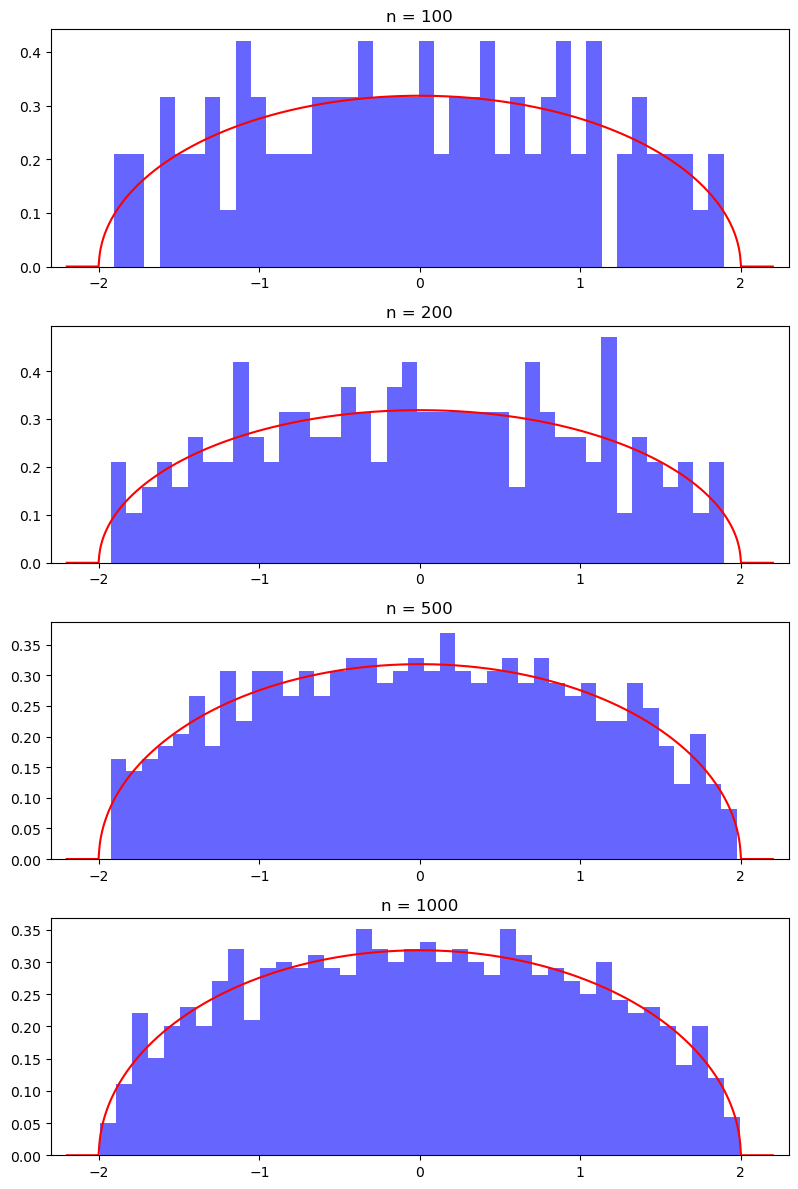

In [38]:
import matplotlib.pyplot as plt

ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(8, 12))
x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = np.array([wigner_density(t) for t in x_curve])

for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    spec = get_spectrum(Z)
    ax.hist(spec, bins=40, density=True, color="b", alpha=0.6)
    ax.plot(x_curve, y_curve, color="r")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.3, 2.3)

plt.tight_layout()
plt.show()


## 任务2‑1 生命游戏校验棋盘 is_valid_board(board)
任务：判断numpy数组是否为有效生命游戏棋盘：二维数组，元素只能是0或1，返回布尔值。


In [39]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0,1])):
        return False
    return True

# 测试
b1 = np.array([[1,0],[0,1]])
print(is_valid_board(b1))


True


## 任务2‑2 生命游戏单步迭代 gol_step(board)
任务：输入m×n棋盘，先校验合法性，非法抛异常；使用**原棋盘状态**、环绕边界计算8邻域，返回下一代棋盘。
更新规则：
1.活细胞：邻居<2死亡；2‑3存活；>3死亡
2.死细胞：恰好3邻居复活，其余保持死亡


In [40]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘格式非法")
    m, n = board.shape
    new_board = np.zeros_like(board)
    for i in range(m):
        for j in range(n):
            cnt = 0
            for di in (-1,0,1):
                for dj in (-1,0,1):
                    if di==0 and dj==0:
                        continue
                    ni = (i + di) % m
                    nj = (j + dj) % n
                    cnt += board[ni, nj]
            cur = board[i,j]
            if cur == 1:
                if cnt ==2 or cnt ==3:
                    new_board[i,j] =1
                else:
                    new_board[i,j]=0
            else:
                if cnt ==3:
                    new_board[i,j]=1
    return new_board

#测试
test_board = np.array([[0,1,0],[0,1,0],[0,1,0]])
next_b = gol_step(test_board)
print(next_b)


[[1 1 1]
 [1 1 1]
 [1 1 1]]


## 任务2‑3 绘制生命游戏棋盘 draw_gol_board(board)
任务：绘图；活细胞黑色，死细胞白色；隐藏坐标轴、刻度，不显示网格。


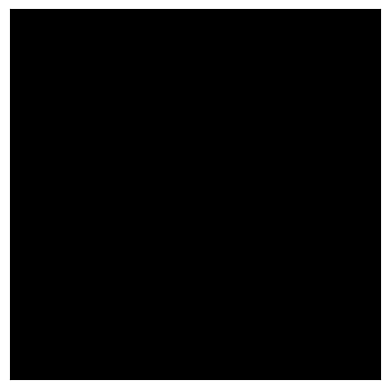

In [41]:
def draw_gol_board(board):
    plt.figure()
    plt.imshow(board, cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

draw_gol_board(next_b)


## 任务3‑1 pandas读取iris数据集
任务：读取iris.csv，输出：样本数量、各列数据类型、列名、花卉种类数目。
> 注意：iris.csv放置在notebook同目录。


In [42]:
import pandas as pd
# 读取你的iris文件
df = pd.read_csv("iris.csv")
# 重命名列，去掉cm、空格，改成下划线
df.rename(columns={
    "sepal length (cm)": "sepal_length",
    "sepal width (cm)": "sepal_width",
    "petal length (cm)": "petal_length",
    "petal width (cm)": "petal_width"
}, inplace=True)
# 手动补上species（经典iris前50 setosa，51-100 versicolor，101-150 virginica）
df["species"] = "setosa"
df.loc[50:99, "species"] = "versicolor"
df.loc[100:149, "species"] = "virginica"

print("样本总数：", len(df))
print("\n各列数据类型：")
print(df.dtypes)
print("\n列名：")
print(df.columns.tolist())
print("\n花卉种类数目：", df["species"].nunique())
print("\n花卉种类：", df["species"].unique())



样本总数： 150

各列数据类型：
Unnamed: 0        int64
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

列名：
['Unnamed: 0', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类数目： 3

花卉种类： ['setosa' 'versicolor' 'virginica']


## 任务3‑2 修改错误数据行
任务：
索引34（原35行）修改为：4.9,3.1,1.5,0.2,"setosa"
索引37（原38行）修改为：4.9,3.6,1.4,0.1,"setosa"
修改完成打印两行校验。


In [43]:
# 只对需要的4个数值列+species单独赋值，不操作Unnamed:0
df.loc[34, ["sepal_length","sepal_width","petal_length","petal_width","species"]] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, ["sepal_length","sepal_width","petal_length","petal_width","species"]] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("校验修改行：")
print(df.loc[[34, 37]])



校验修改行：
    Unnamed: 0  sepal_length  sepal_width  petal_length  petal_width species
34          34           4.9          3.1           1.5          0.2  setosa
37          37           4.9          3.6           1.4          0.1  setosa


## 任务3‑3 添加新比率列
任务：新增
`Petal.Ratio` = 花瓣长度 / 花瓣宽度
`Sepal.Ratio` = 萼片长度 / 萼片宽度


In [44]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print(df[["petal_length","petal_width","Petal.Ratio","sepal_length","sepal_width","Sepal.Ratio"]].head())


   petal_length  petal_width  Petal.Ratio  sepal_length  sepal_width  \
0           1.4          0.2          7.0           5.1          3.5   
1           1.4          0.2          7.0           4.9          3.0   
2           1.3          0.2          6.5           4.7          3.2   
3           1.5          0.2          7.5           4.6          3.1   
4           1.4          0.2          7.0           5.0          3.6   

   Sepal.Ratio  
0     1.457143  
1     1.633333  
2     1.468750  
3     1.483871  
4     1.388889  


## 任务3‑4 保存修正数据集
任务：保存处理后数据为 iris_corrected.csv，输出到当前工作目录，需要随作业提交。


In [45]:
df.to_csv("iris_corrected.csv", index=False)
print("文件已保存 iris_corrected.csv")


文件已保存 iris_corrected.csv


## 任务3‑5 分组聚合统计
任务：按花卉species分组，针对 Petal.Ratio、Sepal.Ratio 计算：均值、中位数、最小值、最大值、标准差。


In [46]:
agg_funcs = ["mean", "median", "min", "max", "std"]
res = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(agg_funcs)
print(res)


           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
